# Fast Track AI

Desafio de analise de crédito

Informações e instruções sobre o desafio: https://github.com/LucasKiraly/fast-track-ia-t1/tree/main/desafios/analise-credito




## 🎯 Desafio

A equipe da CredAIR precisa utilizar o histórico de propostas para compreender melhor os fatores relacionados à inadimplência e investigar se é possível utilizar as informações disponíveis para apoiar a identificação de propostas de maior risco.

A partir dos dados fornecidos, desenvolva uma análise que percorra as principais etapas de um projeto de Ciência de Dados e Machine Learning.

Não existe uma única forma correta de realizar todas as etapas. Suas escolhas devem ser justificadas de acordo com o problema e com as características dos dados.

### 1. Entendimento do problema

Analise o contexto apresentado e as variáveis disponíveis.

Você deverá:

* identificar a variável resposta do problema;
* explicar o que essa variável representa;
* caracterizar o problema de Machine Learning;
* justificar por que o problema pode ser tratado como um problema de **classificação**.

## Resposta para o entendimento do problema:

- A CredAIR quer avaliar os fatores de inadimplência dos clientes para identificar propostas de crédito com maior risco.
- **Variável resposta (target):** `inadimplente`, onde `0` indica proposta que não resultou em inadimplência e `1` indica proposta que resultou em inadimplência.
- **Variáveis preditoras (features):** informações cadastrais, financeiras e características do empréstimo disponíveis no momento da proposta.
- **Tipo de aprendizado:** supervisionado, pois possuímos exemplos históricos com rótulo conhecido.
- **Por que o problema pode ser tratado como "Problema de Classificação"?** O problema pode ser de classificação porque queremos identificar uma de duas classes, que no caso seria se o cliente será inadimplênte, onde se `1` é inadimplente e se `0` não é inadimplente.

-----------------------------------------------------------------------------------------------------

### 2. Análise exploratória

Investigue os dados antes de realizar a modelagem.

Sua análise deverá:

- 2.1 apresentar as principais características dos dados;
- 2.2 analisar a distribuição da variável resposta;
- 2.3 investigar relações entre as variáveis e a inadimplência;
- 2.4 destacar padrões ou comportamentos relevantes encontrados durante a análise.
- 2.5 conclusões da EDA

Utilize tabelas, estatísticas e visualizações quando forem relevantes para sustentar suas conclusões.

------------------------------------------------------------------------------------------------------

## 2. Análise exploratória dos dados (EDA)

**Objetivo:** conhecer o conjunto, a distribuição das classes e as relações entre variáveis antes de modelar ou alterar os dados brutos.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})
pd.set_option("display.max_columns", 30)

df_bruto = pd.read_csv("../dados/credito.csv")

print(f"Dimensões: {df_bruto.shape[0]:,} registros x {df_bruto.shape[1]} colunas")

print("5 primeiras linhas do arquivo 'credito.csv'")
display(df_bruto.head())

Dimensões: 5,000 registros x 11 colunas
5 primeiras linhas do arquivo 'credito.csv'


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,2911.82,14,690,5934.19,60,Viagem,1,0
1,49,RR,Ensino Médio,3176.43,5,676,6791.38,24,Outros,2,0
2,48,AL,Ensino Superior,3429.40,23,558,14666.78,24,Outros,5,1
3,59,GO,Ensino Fundamental,10096.70,2,739,19053.24,24,Reforma,0,0
4,37,RJ,Ensino Fundamental,3033.25,24,797,6171.31,6,Educação,0,1


### 2.1 Tipos, preenchimento e estatísticas

O método `info()` revela o tipo inferido pelo Pandas e quantos valores não nulos existem.



In [2]:
df_bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   idade               5000 non-null   int64  
 1   estado              5000 non-null   str    
 2   escolaridade        5000 non-null   str    
 3   renda_mensal        5000 non-null   float64
 4   tempo_emprego_anos  5000 non-null   int64  
 5   score_credito       5000 non-null   int64  
 6   valor_solicitado    5000 non-null   float64
 7   prazo_meses         5000 non-null   int64  
 8   finalidade          5000 non-null   str    
 9   dividas_ativas      5000 non-null   int64  
 10  inadimplente        5000 non-null   int64  
dtypes: float64(2), int64(6), str(3)
memory usage: 429.8 KB


O método `describe()` mostra estatísticas como média, quartis e extremos. Ausência de valores nulos **não** garante ausência de erros.

In [3]:
df_bruto.describe()

,idade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,dividas_ativas,inadimplente
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,47.767400,5228.633582,12.662200,652.481200,14264.657378,29.922000,1.900400,0.344000
std,31.646099,3968.478198,7.517539,84.817076,8268.261465,15.482515,1.864719,0.475089
min,18.000000,100.000000,1.000000,335.000000,1721.480000,6.000000,0.000000,0.000000
25%,32.000000,2697.320000,6.000000,594.000000,8467.170000,18.000000,0.000000,0.000000
50%,46.000000,4146.300000,13.000000,653.000000,12365.630000,24.000000,1.000000,0.000000
75%,61.000000,6458.877500,19.000000,710.000000,17764.885000,36.000000,3.000000,1.000000
max,750.000000,44814.190000,74.000000,850.000000,50000.000000,60.000000,7.000000,1.000000


### 2.2 Distribuição da resposta

A média de uma coluna com valores 0 e 1 é igual à proporção de registros com valor 1. É importante conhecer o desequilíbrio entre classes, porque um modelo que sempre prevê a classe majoritária pode obter boa acurácia sem detectar inadimplência.

Quantidade por classe:
inadimplente
0    3280
1    1720
Name: count, dtype: int64
Taxa de inadimplência: 34.40%


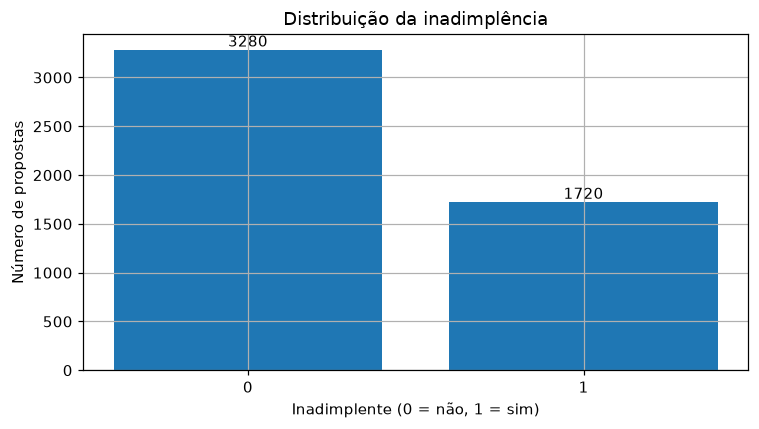

In [4]:
distribuicao = df_bruto["inadimplente"].value_counts().sort_index()
print("Quantidade por classe:")
print(distribuicao)
print(f"Taxa de inadimplência: {df_bruto['inadimplente'].mean():.2%}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(distribuicao.index.astype(str), distribuicao.values)
ax.set(title="Distribuição da inadimplência", xlabel="Inadimplente (0 = não, 1 = sim)", ylabel="Número de propostas")
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
plt.tight_layout()
plt.show()

### 2.3 Relações iniciais entre as variáveis e a inadimplência

Neste passo, comparamos grupos de clientes, sem afirmar causalidade, pois estamos apenas analisando a base para formar hipoteses.
Por exemplo, não podemos afirmar que um score médio menor entre inadimplentes é causa da inadimplência.

In [5]:
comparacao = df_bruto.groupby("inadimplente").agg(
    propostas=("inadimplente", "size"),
    score_medio=("score_credito", "mean"),
    renda_mediana=("renda_mensal", "median"),
    dividas_media=("dividas_ativas", "mean")
).round(2)
display(comparacao)

,propostas,score_medio,renda_mediana,dividas_media
inadimplente,,,,
0,3280,671.02,4606.35,1.67
1,1720,617.13,3330.64,2.34


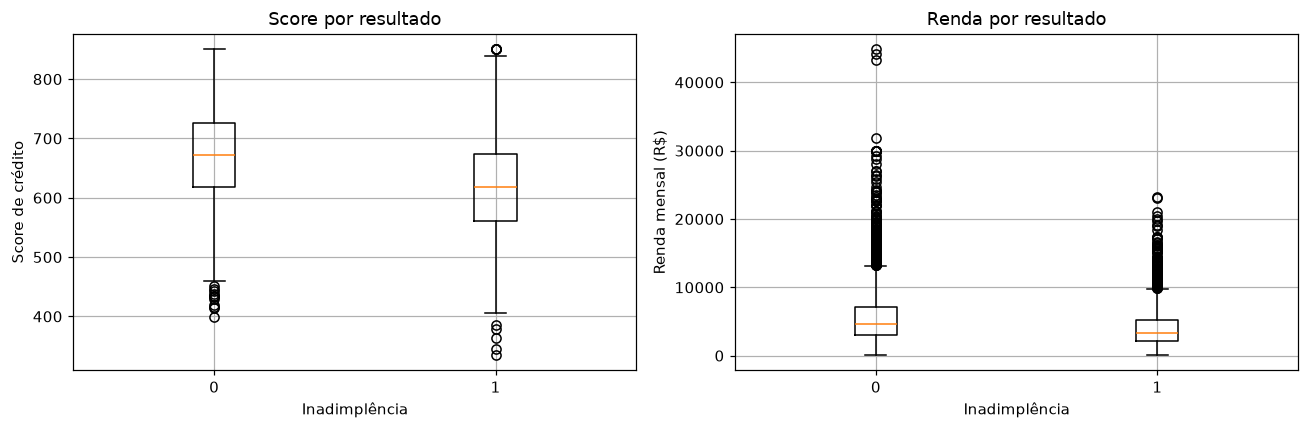

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].boxplot([df_bruto.loc[df_bruto.inadimplente == x, "score_credito"] for x in [0, 1]], tick_labels=["0", "1"])
axs[0].set(title="Score por resultado", xlabel="Inadimplência", ylabel="Score de crédito")
axs[1].boxplot([df_bruto.loc[df_bruto.inadimplente == x, "renda_mensal"] for x in [0, 1]], tick_labels=["0", "1"])
axs[1].set(title="Renda por resultado", xlabel="Inadimplência", ylabel="Renda mensal (R$)")
plt.tight_layout()
plt.show()

### 2.4 Taxa de inadimplência por número de dívidas ativas e faixas de score

Neste passo, é realizado o cálculo da taxa de inadimplência em cada grupo com `mean()` (média) da variável binária.
Também mostramos a quantidade de propostas.

Inadimplência por quantidade de dívidas ativas

Taxa de inadimplência e quantidade de propostas por quantidade de dívidas ativas


,propostas,taxa_inadimplencia_pct
dividas_ativas,,
0,1554,27.4
1,965,26.8
2,848,36.3
3,631,38.7
4,420,46.2
5,322,45.7
6,162,51.2
7,98,60.2


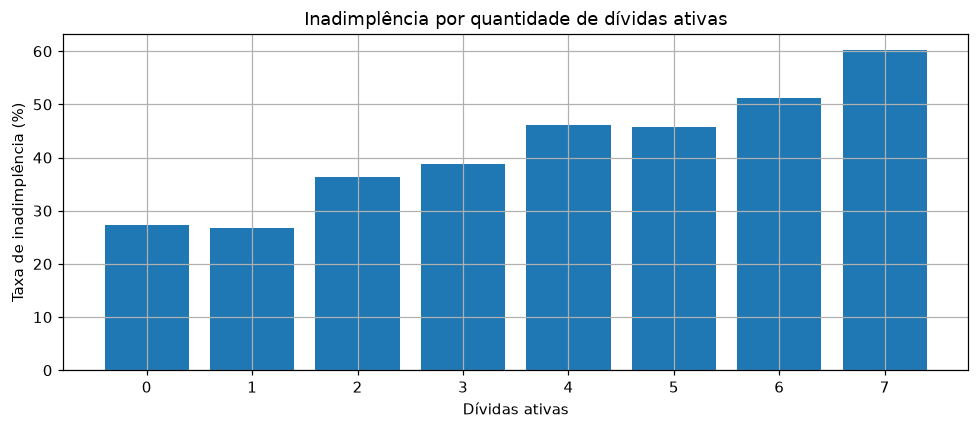

In [7]:
por_dividas = df_bruto.groupby("dividas_ativas").agg(
    propostas=("inadimplente", "size"),
    taxa_inadimplencia=("inadimplente", "mean")
)
print("Taxa de inadimplência e quantidade de propostas por quantidade de dívidas ativas")
por_dividas["taxa_inadimplencia_pct"] = (por_dividas["taxa_inadimplencia"] * 100).round(1)
display(por_dividas[["propostas", "taxa_inadimplencia_pct"]])

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(por_dividas.index.astype(str), por_dividas["taxa_inadimplencia_pct"])
ax.set(title="Inadimplência por quantidade de dívidas ativas", xlabel="Dívidas ativas", ylabel="Taxa de inadimplência (%)")
plt.tight_layout()
plt.show()

Taxa de inadimplência por faixa de score de crédito com proposta.

Taxa de inadimplência por faixa de score de crédito com proposta


,propostas,taxa_inadimplencia_pct
score_credito,,
"(334.999, 581.0]",1017,55.9
"(581.0, 632.0]",1009,41.1
"(632.0, 675.0]",977,32.1
"(675.0, 725.0]",1014,25.9
"(725.0, 850.0]",983,16.2


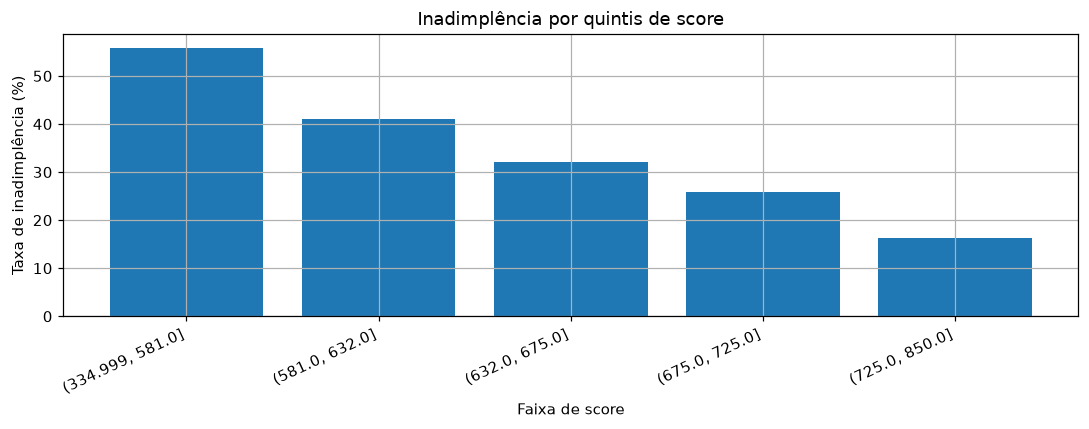

In [8]:
print("Taxa de inadimplência por faixa de score de crédito com proposta")
faixa_score = pd.qcut(df_bruto["score_credito"], q=5, duplicates="drop")
por_score = df_bruto.groupby(faixa_score, observed=True)["inadimplente"].agg(["size", "mean"])
por_score.columns = ["propostas", "taxa_inadimplencia"]
por_score["taxa_inadimplencia_pct"] = (por_score["taxa_inadimplencia"] * 100).round(1)
display(por_score[["propostas", "taxa_inadimplencia_pct"]])

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(por_score.index.astype(str), por_score["taxa_inadimplencia_pct"])
ax.set(title="Inadimplência por quintis de score", xlabel="Faixa de score", ylabel="Taxa de inadimplência (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 2.5 Conclusões e Hipoteses sobre a EDA

- A classe `1` (inadimplência) corresponde a cerca de 34,4% das propostas, portanto não é a classe majoritária.
- Na amostra, inadimplentes apresentam **score médio e renda mediana menores**, além de **mais dívidas ativas** em média.
- As taxas observadas de inadimplência **tendem a aumentar** com o número de dívidas e **a diminuir** conforme o score aumenta.
- Há inconsistências importantes em `idade` e `estado`, onde aparecem idades com valor muito alto (Ex: "750") e estados com espaços junto ao preenchimento da 'UF' (Ex:" DF ").


-----------------------------------------------------------------------------------------------------

## 3. Diagnóstico e limpeza de dados

**Objetivo:** Remover duplicatas, tratar os espaços no campo UF, identificar idade e tempo de emprego inválidos.

**Decisões:**
- 3.1 Verificar ausências e duplicatas antes de tratar.
- 3.2 Remover registros duplicados, pois não dá para determinar se a repetição é cópia de uma linha ou se é dado real.
- 3.3 Padronizar `estado` removendo espaços e convertendo para maiúsculas.
- 3.4 Substituir idades fora de 18–120 anos por `NaN`, assumindo a premissa de que ninguém menor de 18 e maior que 120 anos possa solicitar uma proposta.
- 3.5 Substituir `tempo_emprego_anos > idade` por `NaN`, pois não é possível que alguém tenha mais tempo de serviço do que tempo de vida.
- 3.6 Imputar as ausencias apenas após dividir a base em treino e teste, usando mediana aprendida no treino, via pipeline, para evitar vazamento estatístic.


In [9]:
print("Nulos na base original:")
display(df_bruto.isna().sum().to_frame("nulos"))
print("Duplicatas exatas:", df_bruto.duplicated().sum())
print("Idades fora de 18–120:", ((df_bruto["idade"] < 18) | (df_bruto["idade"] > 120)).sum())
print("Tempo de emprego maior que idade:", (df_bruto["tempo_emprego_anos"] > df_bruto["idade"]).sum())
print("Estados distintos antes da padronização:", df_bruto["estado"].nunique())
print("UFs com espaços extras:", (df_bruto["estado"] != df_bruto["estado"].str.strip()).sum())

Nulos na base original:


,nulos
idade,0
estado,0
escolaridade,0
renda_mensal,0
tempo_emprego_anos,0
score_credito,0
valor_solicitado,0
prazo_meses,0
finalidade,0
dividas_ativas,0


Duplicatas exatas: 19
Idades fora de 18–120: 15
Tempo de emprego maior que idade: 8
Estados distintos antes da padronização: 85
UFs com espaços extras: 101


Removendo duplicatas de toda a base.

Removendo os espaços na coluna `estado` e convertendo todas as letras em maiúsculas. 

In [10]:
df = df_bruto.drop_duplicates().copy()
df["estado"] = df["estado"].astype("string").str.strip().str.upper()



Idade impossível ou incompatível com a população que solicita proposta de crédito.

In [11]:
idade_invalida = ~df["idade"].between(18, 120)
df.loc[idade_invalida, "idade"] = np.nan


Não faz sentido alguém estar empregado há mais anos do que sua própria idade.

In [12]:
tempo_invalido = (df["tempo_emprego_anos"] < 0) | (df["tempo_emprego_anos"] > df["idade"])
df.loc[tempo_invalido, "tempo_emprego_anos"] = np.nan



Verificando valores:
- se `inadimplente` contém apenas `0` ou `1` como valor.
- se não há zeros ou negativos nas outras variáveis, como `renda_mensal`, `valor_solicitado`, `prazo_meses` e `dividas_ativas`.


In [13]:
assert df["inadimplente"].isin([0, 1]).all()
assert (df["renda_mensal"] > 0).all()
assert (df["valor_solicitado"] > 0).all()
assert (df["prazo_meses"] > 0).all()
assert (df["dividas_ativas"] >= 0).all()

### Resultado após o tratamento

In [14]:
print("Propostas após remover duplicatas:", len(df))
print("UFs distintas após tratamento:", df["estado"].nunique())
print("Ausências convertidas (em NaN) para tratamento controlado:")
print(df.isna().sum()[df.isna().sum() > 0])

Propostas após remover duplicatas: 4981
UFs distintas após tratamento: 27
Ausências convertidas (em NaN) para tratamento controlado:
idade                 15
tempo_emprego_anos     8
dtype: int64


## 4. Engenharia de atributos

Criando a variável derivada **`multiplo_renda_solicitado`**:

`multiplo_renda_solicitado = valor_solicitado / renda_mensal`

O resultado mostra a quantos meses de renda corresponde o valor solicitado. Exemplo: R$ 12 mil solicitados / R$ 4 mil mensais = 3 meses de renda.

**Hipótese:** propostas com valores elevados em relação à renda podem apresentar maior risco. **Não é comprometimento mensal de renda**, pois não conhecemos taxas de juros que pode modificar o valor final da dívida.

Esta variável estará disponível no momento da proposta e será incluída no modelo.

In [15]:
df["multiplo_renda_solicitado"] = df["valor_solicitado"] / df["renda_mensal"]
assert np.isfinite(df["multiplo_renda_solicitado"]).all()

print(df["multiplo_renda_solicitado"].describe().round(2))
display(df.groupby("inadimplente")["multiplo_renda_solicitado"].agg(["median", "mean"]).round(2))

count    4981.00
mean        4.26
std         5.60
min         0.13
25%         1.67
50%         2.96
75%         5.27
max       200.01
Name: multiplo_renda_solicitado, dtype: float64


,median,mean
inadimplente,,
0,2.55,3.43
1,4.21,5.83


Analisando a variável derivada `multiplo_renda_mensal`, entende-se que os inadimplêntes solicitam valores muito altos, na média de 5.83 vezes o valor da renda mensal.

A mediana é de 4.21 vezes o valor da renda mensal, ou seja, um valor muito acima dos ganhos do solicitante.

Sem contar que não sabemos a taxa de juros, que dependendo, pode levar a um valor total devido muito maior.

Além disso, há um caso bem interessante: o maior valor da variável derivada `multiplo_renda_mensal` é de 200.01, ou seja, pouco mais de 200 vezes o valor da renda. Exemplo: solicitou R$ 200.000 com renda de R$ 1.000.

Supostamente é possível solicitar um valor muito maior que renda mensal, não podendo afirmar se há um valor limite para solicitação.

Foi feito um levantamento dos Top 10 `multiplo_renda_mensal`, para verificar a relação entre renda mensal e o valor solicitado:

In [16]:
colunas = [
    "renda_mensal",
    "valor_solicitado",
    "prazo_meses",
    "multiplo_renda_solicitado",
    "inadimplente"
]

print("Os Top 10 maiores múltiplos de renda mensal")
display(
    df.nlargest(
        10,
        "multiplo_renda_solicitado"
    )[colunas]
)

Os Top 10 maiores múltiplos de renda mensal


,renda_mensal,valor_solicitado,prazo_meses,multiplo_renda_solicitado,inadimplente
2626,100.00,20001.16,24,200.011600,0
4870,150.00,25384.28,24,169.228533,1
3875,350.00,22425.30,36,64.072286,1
431,250.00,15819.19,36,63.276760,1
4795,200.00,12576.22,60,62.881100,0
3801,450.00,26664.24,24,59.253867,1
4895,922.57,40657.55,18,44.069881,1
3065,1037.25,44030.76,24,42.449516,1
2864,918.92,37273.47,24,40.562258,1
370,900.00,36504.00,48,40.560000,1


-------------------------------------------------------------------

## 5. Preparação para modelagem

**Divisão:** 80% treino, 20% teste, com `stratify=y` para preservar aproximadamente a proporção de adimplentes/inadimplentes. O conjunto de teste só será utilizado na avaliação final.

O parâmetro `stratify=y` na função train_test_split do Scikit-learn garante que a proporção de classes da variável-alvo (y) seja idêntica (ou muito próxima) entre os conjuntos de treino e de teste

**Pipeline:**
- Numéricas: preencher ausências com a **mediana do treino** e aplicar **StandardScaler** (centralização/escala) para facilitar o ajuste da Regressão Logística.
- Categóricas: preencher eventuais ausências com a moda do treino e aplicar **OneHotEncoder** para converter categorias em indicadores numéricos. `handle_unknown="ignore"` tolera categorias novas no teste.
- O pipeline ajusta essas transformações no conjunto de treino, evitando estimar medianas e escalas com informações do teste.

**Escolha de variáveis:** todas as variáveis originais de entrada, mais a derivada. A resposta `inadimplente` é explicitamente excluída. Em cenário real, avaliaríamos cuidadosamente atributos potencialmente sensíveis e os requisitos legais/éticos antes de aplicá-los.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, classification_report
)
from sklearn.inspection import permutation_importance

X = df.drop(columns="inadimplente")
y = df["inadimplente"].astype(int)

colunas_numericas = X.select_dtypes(include="number").columns.tolist()
colunas_categoricas = X.select_dtypes(exclude="number").columns.tolist()

print("Variáveis numéricas:", colunas_numericas)
print("Variáveis categóricas:", colunas_categoricas)

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

transformador_numerico = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("padronizador", StandardScaler())
])
transformador_categorico = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("codificador", OneHotEncoder(handle_unknown="ignore"))
])

preprocessador = ColumnTransformer([
    ("numericas", transformador_numerico, colunas_numericas),
    ("categoricas", transformador_categorico, colunas_categoricas)
])

print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)
print("Taxa classe 1 | Treino:", round(y_treino.mean(), 4), "| Teste:", round(y_teste.mean(), 4))

Variáveis numéricas: ['idade', 'renda_mensal', 'tempo_emprego_anos', 'score_credito', 'valor_solicitado', 'prazo_meses', 'dividas_ativas', 'multiplo_renda_solicitado']
Variáveis categóricas: ['estado', 'escolaridade', 'finalidade']
Treino: (3984, 11) | Teste: (997, 11)
Taxa classe 1 | Treino: 0.3444 | Teste: 0.344


---------------------------------------------------------

## 6. Modelagem — Regressão Logística

A Regressão Logística é um classificador supervisionado que estima probabilidades de pertencer à classe 1. A função sigmoide converte uma combinação linear das variáveis em um valor entre 0 e 1.

**Por que foi escolhida?** É o modelo exigido pelo desafio, fornece probabilidades e permite interpretar o sentido dos coeficientes. Começamos sem ajuste de hiperparâmetros: `max_iter=2000` é aumentado para favorecer convergência.

Também treinamos uma **referência simples**: `DummyClassifier(strategy="most_frequent")`, que sempre prevê a classe mais comum do treino. Se nosso modelo não superar uma referência tão simples, sua utilidade seria questionável.

In [18]:
modelo = Pipeline([
    ("preprocessamento", preprocessador),
    ("classificador", LogisticRegression(max_iter=2000, random_state=42))
])
modelo.fit(X_treino, y_treino)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_treino, y_treino)

print("Regressão Logística e baseline treinados com o conjunto de treino.")

Regressão Logística e baseline treinados com o conjunto de treino.


-----------------------------------------------

## 7. Avaliação e interpretação

**Usamos apenas o conjunto de teste**, que não participou do ajuste do modelo. Comparamos os dois classificadores.

- **Acurácia:** proporção de previsões corretas.
- **Precision (classe 1):** entre os previstos como inadimplentes, quantos realmente foram?
- **Recall (classe 1):** entre os realmente inadimplentes, quantos foram identificados?
- **F1:** média harmônica de precision e recall.
- **ROC-AUC:** mede a capacidade de ordenação entre as classes considerando diferentes limiares; 0,5 indica ordenação aleatória.

O limiar de classificação padrão é 0,50. Alterá-lo exige considerar custos de falsos positivos/falsos negativos e idealmente validação separada. Não faremos ajuste no teste.

In [19]:
def avaliar(nome, estimador):
    previsto = estimador.predict(X_teste)
    probabilidade = estimador.predict_proba(X_teste)[:, 1]
    return {
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, previsto),
        "Precision": precision_score(y_teste, previsto, zero_division=0),
        "Recall": recall_score(y_teste, previsto, zero_division=0),
        "F1": f1_score(y_teste, previsto, zero_division=0),
        "ROC-AUC": roc_auc_score(y_teste, probabilidade)
    }

comparativo = pd.DataFrame([
    avaliar("Baseline (classe majoritária)", baseline),
    avaliar("Regressão Logística", modelo)
]).set_index("Modelo")
display(comparativo.round(3))

previsoes = modelo.predict(X_teste)
probabilidades = modelo.predict_proba(X_teste)[:, 1]
print("Relatório do modelo:")
print(classification_report(y_teste, previsoes, target_names=["Adimplente", "Inadimplente"], zero_division=0))

,Acurácia,Precision,Recall,F1,ROC-AUC
Modelo,,,,,
Baseline (classe majoritária),0.656,0.000,0.000,0.000,0.500
Regressão Logística,0.733,0.662,0.458,0.541,0.766


Relatório do modelo:
              precision    recall  f1-score   support

  Adimplente       0.76      0.88      0.81       654
Inadimplente       0.66      0.46      0.54       343

    accuracy                           0.73       997
   macro avg       0.71      0.67      0.68       997
weighted avg       0.72      0.73      0.72       997



### 7.1 Matriz de confusão

Como consideramos `inadimplente=1` a classe positiva:
- **TN:** adimplente previsto como adimplente.
- **FP:** adimplente previsto como inadimplente.
- **FN:** inadimplente previsto como adimplente — risco não detectado.
- **TP:** inadimplente previsto como inadimplente.

A matriz mostra que uma acurácia razoável pode coexistir com vários inadimplentes não identificados.

TN=574 | FP=80 | FN=186 | TP=157


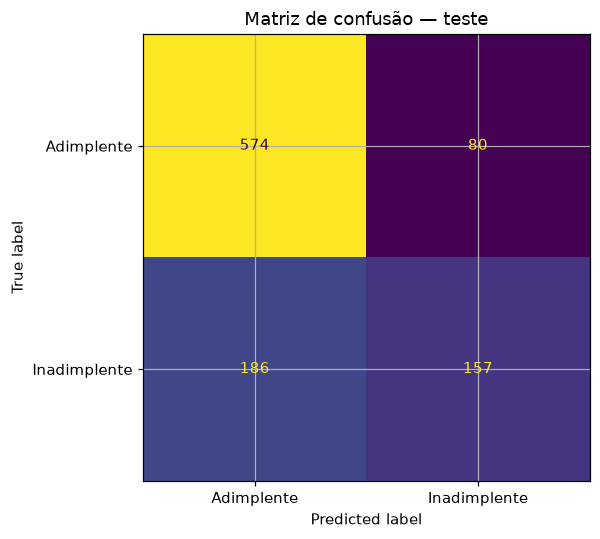

In [20]:
matriz = confusion_matrix(y_teste, previsoes, labels=[0, 1])
tn, fp, fn, tp = matriz.ravel()
print(f"TN={tn} | FP={fp} | FN={fn} | TP={tp}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=["Adimplente", "Inadimplente"]).plot(ax=ax, values_format="d", colorbar=False)
ax.set_title("Matriz de confusão — teste")
plt.tight_layout()
plt.show()

### 7.2 Curva ROC

A curva compara a taxa de verdadeiros positivos com a de falsos positivos sob diferentes limiares. A área ROC-AUC serve como indicador complementar de separação/ordenação, não como medida de lucro ou de calibração das probabilidades.

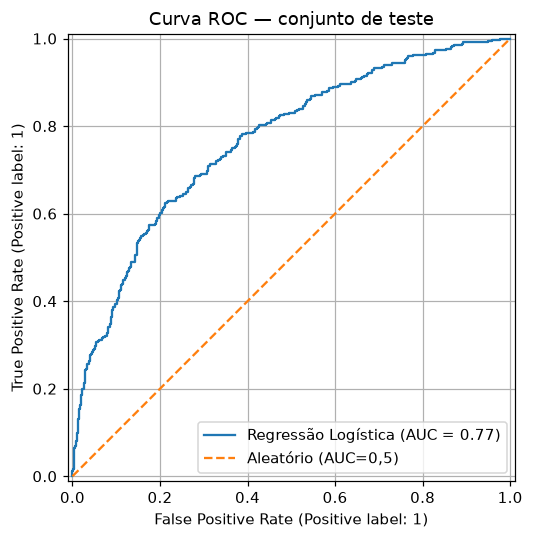

In [21]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(modelo, X_teste, y_teste, ax=ax, name="Regressão Logística")
ax.plot([0, 1], [0, 1], "--", label="Aleatório (AUC=0,5)")
ax.set_title("Curva ROC — conjunto de teste")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 7.3 Quais variáveis estão mais relacionadas às previsões?

Aplicamos **importância por permutação**: embaralhamos os valores de cada variável no teste e medimos a queda média de ROC-AUC. Se a qualidade cair muito, o modelo dependia daquela informação. A medida é **preditiva, não causal**, pode ser afetada por variáveis correlacionadas e aqui é usada somente para interpretação, não para escolher outro modelo usando o teste.

,variavel,queda_media_auc,desvio_queda
5,score_credito,0.1299,0.0133
9,dividas_ativas,0.0332,0.0061
10,multiplo_renda_solicitado,0.0212,0.0032
3,renda_mensal,0.0181,0.0041
7,prazo_meses,0.0149,0.0025
4,tempo_emprego_anos,0.0096,0.0024
6,valor_solicitado,0.0026,0.0015
0,idade,0.0023,0.0025
2,escolaridade,0.0002,0.0010
8,finalidade,-0.0005,0.0011


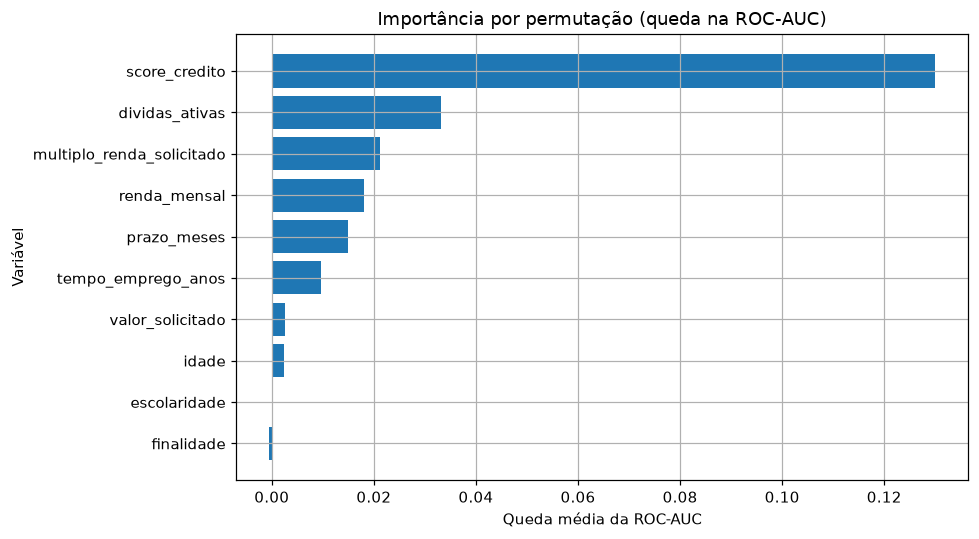

In [22]:
importancias = permutation_importance(
    modelo, X_teste, y_teste, scoring="roc_auc", n_repeats=8,
    random_state=42, n_jobs=1
)
importancia_df = pd.DataFrame({
    "variavel": X_teste.columns,
    "queda_media_auc": importancias.importances_mean,
    "desvio_queda": importancias.importances_std
}).sort_values("queda_media_auc", ascending=False)
display(importancia_df.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importancia_df.head(10)["variavel"], importancia_df.head(10)["queda_media_auc"])
ax.invert_yaxis()
ax.set(title="Importância por permutação (queda na ROC-AUC)", xlabel="Queda média da ROC-AUC", ylabel="Variável")
plt.tight_layout()
plt.show()

### 7.4 Coeficientes da Regressão Logística

Coeficiente positivo tende a elevar o *log-odds* (e, mantido o restante constante, a probabilidade) da classe 1; coeficiente negativo tende a reduzi-lo. **Coeficiente não implica causalidade.** Variáveis numéricas foram padronizadas, enquanto categóricas foram codificadas, portanto comparar diretamente magnitudes entre todos os coeficientes exige cautela. Também há categorias correlacionadas e regularização por padrão.

In [23]:
nomes_atributos = modelo.named_steps["preprocessamento"].get_feature_names_out()
coeficientes = modelo.named_steps["classificador"].coef_[0]
coef_df = pd.DataFrame({"atributo_transformado": nomes_atributos, "coeficiente": coeficientes})
coef_df["magnitude"] = coef_df["coeficiente"].abs()
display(coef_df.sort_values("magnitude", ascending=False).head(15).drop(columns="magnitude").round(4))

,atributo_transformado,coeficiente
3,numericas__score_credito,-0.7941
7,numericas__multiplo_renda_solicitado,0.5321
6,numericas__dividas_ativas,0.4524
1,numericas__renda_mensal,-0.3874
15,categoricas__estado_ES,-0.3255
13,categoricas__estado_CE,0.2980
28,categoricas__estado_RO,-0.2870
30,categoricas__estado_RS,0.2758
17,categoricas__estado_MA,0.2700
2,numericas__tempo_emprego_anos,-0.2512


### 7.5 Interpretação dos resultados observados

No teste fixado com `random_state=42`, a Regressão Logística apresenta cerca de **73,3% de acurácia**, **0,766 de ROC-AUC** e **45,8% de recall para inadimplência**. O baseline de classe majoritária apresenta cerca de **65,6% de acurácia**, mas **0% de recall da classe 1**.

A matriz de confusão registra **157 verdadeiros positivos**, **186 falsos negativos**, **80 falsos positivos** e **574 verdadeiros negativos**. Portanto, o modelo melhora a identificação de risco em relação ao baseline, mas ainda deixa de sinalizar muitos inadimplentes. Sem dados de custo das decisões, não é possível declarar que o modelo seria financeiramente ótimo.

A importância por permutação é exploratória. Interpretamos as variáveis mais relacionadas ao resultado do **modelo ajustado**, não como causas da inadimplência.

-------------------------------------------------------------

## 8. Conclusão e limitações

### Principais achados

1. O conjunto original possui **5.000 propostas**, com **34,4%** de inadimplência.
2. A qualidade exigiu atenção: **19 duplicatas exatas**, **101 UFs com espaços extras** e **15 idades superiores a 120 anos**. O tempo de emprego também apresentou **8** inconsistências em relação à idade.
3. No conjunto sintético, a inadimplência se associa a **scores mais baixos**, **menor renda mediana** e **maior quantidade de dívidas ativas**. Essas relações não demonstram causalidade.
4. Criamos `multiplo_renda_solicitado`, um indicador do valor solicitado em meses de renda, que foi usado como atributo preditor.
5. Uma **Regressão Logística** treinada com Pipeline, em divisão estratificada 80/20, superou a acurácia do baseline e mostrou poder discriminatório moderado (ROC-AUC por volta de 0,766). Contudo, o recall de inadimplentes foi de apenas ~45,8% no limiar padrão.

### Limitações e cuidados em caso real

- **Dados sintéticos:** relações e métricas podem não representar pessoas reais.
- **Sem data das propostas:** foi usada divisão aleatória; em produção, idealmente validaríamos com dados posteriores (teste temporal).
- **Sem definição operacional de inadimplência:** precisamos de horizonte e critério de atraso para reproduzir o alvo.
- **Sem custo econômico de erros:** não é possível escolher um limiar ótimo para a financeira apenas com a acurácia.
- **Potenciais vieses e discriminação:** idade, escolaridade e localização merecem análise específica de equidade e conformidade regulatória antes de qualquer uso real.
- **Modelo não calibrado nem monitorado:** exigiria validação temporal, avaliação de probabilidades, estabilidade, deriva, auditoria e monitoramento.
